# Widmo Fouriera - przykłady teoretyczne

Sztuczne obrazki i ich widma mocy, potem jak FFT układa częstości (1D).

## Przykłady: proste obrazki i ich widma mocy

Każdy wiersz: sztuczny obrazek (lewo) i jego widmo mocy (prawo, skala log). Na co patrzeć:

- **sinus wzdłuż x** - dwie kropki na osi fx w ±1/okres (widmo mocy jest zawsze symetryczne: f i -f to ta sama fala);
- **sinus pod 45°** - kropki obrócone o 45°, na linii prostopadłej do grzbietów;
- **ten sam sinus przesunięty** - widmo mocy identyczne: przesunięcie zmienia tylko fazę, a fazę wyrzucamy;
- **suma dwóch sinusów** - widmo to suma kropek obu fal;
- **gwiazda (gauss)** - w widmie też gauss, ale odwrotnie: im węższa gwiazda, tym szersza plama w widmie;
- **dwie identyczne gwiazdy** - plama gwiazdy pocięta prążkami; prążki prostopadłe do linii łączącej gwiazdy, odstęp = 1 / odległość;
- **kilka gwiazd rozłożonych losowo** - ta sama plama co dla jednej gwiazdy, ale pocięta nieregularnymi plamkami: każda para
  gwiazd daje swoje prążki (inny odstęp, inny kierunek) i wszystkie się nakładają;
- **te same gwiazdy, każda z ghostem przesuniętym o stały wektor** - widmo mnoży się przez prążki prostopadłe do wektora
  przesunięcia, co 1/|d| (tu d = (15, 10) px, |d| = 18 px, odstęp ~0.055 cykla/px), ale przy ghoście 0.3 gwiazdy ich
  kontrast (moc razy 0.49 ... 1.69) ginie w plamkach - patrz "Skąd prążki i plamki";
- **9 gwiazd w siatce co 32 px** - plama pocięta regularną siatką kropek co 1/32 cykla/px (jak siatka dyfrakcyjna);
- **pozioma linia** - pionowa linia w widmie (wzór zmienia się tylko wzdłuż y);
- **biały szum** - widmo płaskie, bez struktury, na poziomie wariancji.

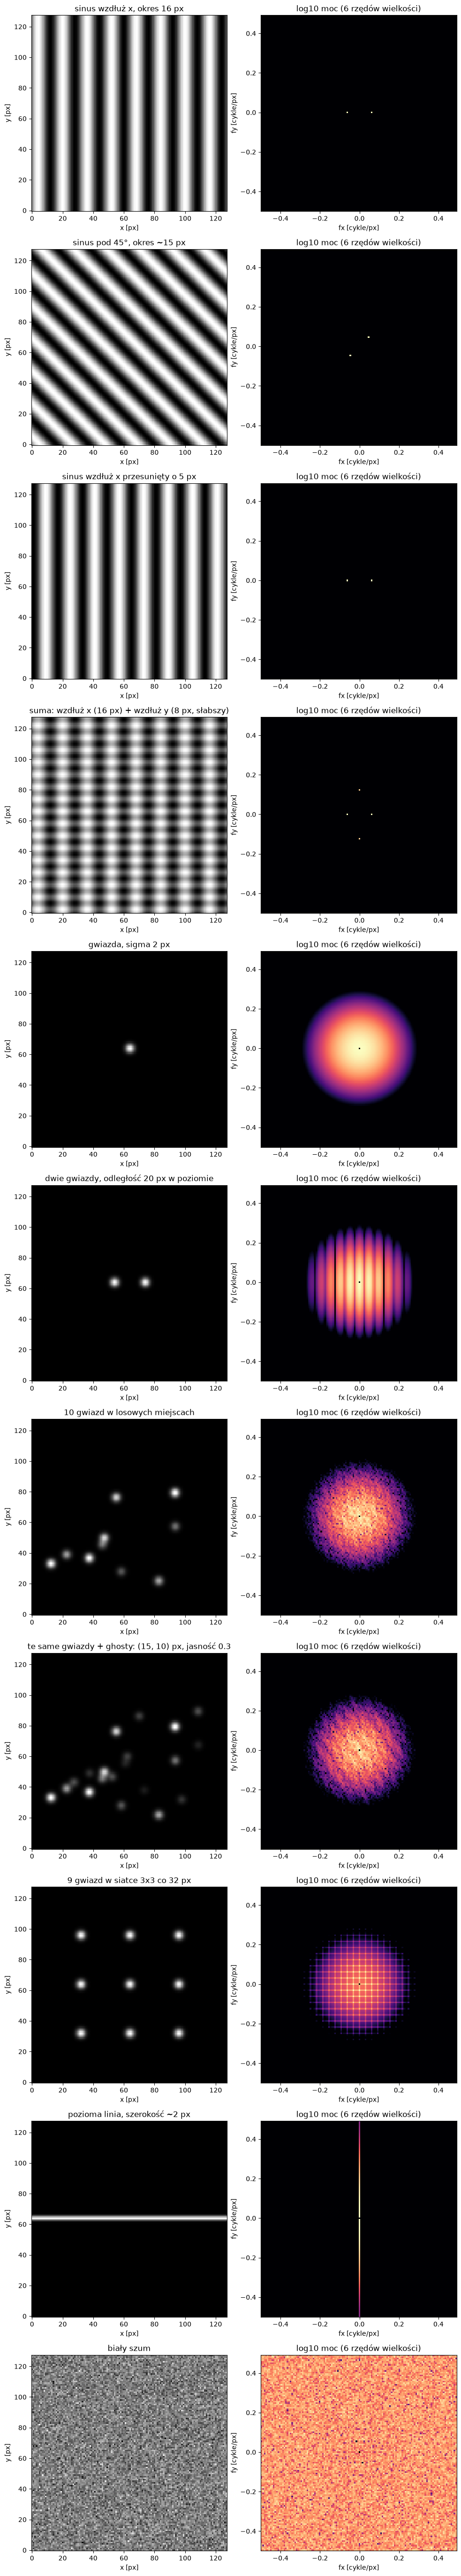

In [13]:
import numpy as np
import matplotlib.pyplot as plt

N = 128                                    # rozmiar obrazków [px]
y, x = np.mgrid[0:N, 0:N]                  # współrzędne każdego piksela
rng = np.random.default_rng(1)

# kilka gwiazd w losowych miejscach, o losowej jasności, sigma 2 px
N_STARS = 10
sx, sy = rng.uniform(10, N - 30, N_STARS), rng.uniform(10, N - 30, N_STARS)   # z dala od prawego i górnego brzegu, żeby zmieściły się ghosty niżej
flux = rng.uniform(0.2, 1, N_STARS)
stars = sum(a * np.exp(-((x - x0)**2 + (y - y0)**2) / (2 * 2**2)) for x0, y0, a in zip(sx, sy, flux))

# te same gwiazdy, każda z ghostem: przesunięty o stały wektor (GX, GY), jasność G_FRAC gwiazdy
GX, GY, G_FRAC = 15, 10, 0.3
ghosts = sum(G_FRAC * a * np.exp(-((x - x0 - GX)**2 + (y - y0 - GY)**2) / (2 * 2**2)) for x0, y0, a in zip(sx, sy, flux))

# 9 gwiazd w równych odstępach: siatka 3x3 co 32 px, ta sama jasność
grid = sum(np.exp(-((x - x0)**2 + (y - y0)**2) / (2 * 2**2)) for x0 in (32, 64, 96) for y0 in (32, 64, 96))

# (tytuł, obrazek); okresy dobrane tak, żeby mieściła się całkowita liczba fal w obrazku
examples = [
    ("sinus wzdłuż x, okres 16 px", np.sin(2 * np.pi * x / 16)),
    ("sinus pod 45°, okres ~15 px", np.sin(2 * np.pi * (6 * x + 6 * y) / N)),
    ("sinus wzdłuż x przesunięty o 5 px", np.sin(2 * np.pi * (x - 5) / 16)),
    ("suma: wzdłuż x (16 px) + wzdłuż y (8 px, słabszy)", np.sin(2 * np.pi * x / 16) + 0.5 * np.sin(2 * np.pi * y / 8)),
    ("gwiazda, sigma 2 px", np.exp(-((x - 64)**2 + (y - 64)**2) / (2 * 2**2))),
    ("dwie gwiazdy, odległość 20 px w poziomie", np.exp(-((x - 54)**2 + (y - 64)**2) / (2 * 2**2)) + np.exp(-((x - 74)**2 + (y - 64)**2) / (2 * 2**2))),
    (f"{N_STARS} gwiazd w losowych miejscach", stars),
    (f"te same gwiazdy + ghosty: ({GX}, {GY}) px, jasność {G_FRAC}", stars + ghosts),
    ("9 gwiazd w siatce 3x3 co 32 px", grid),
    ("pozioma linia, szerokość ~2 px", np.exp(-(y - 64)**2 / (2 * 1**2)) + 0 * x),
    ("biały szum", rng.normal(0, 1, (N, N))),
]

f = np.fft.fftshift(np.fft.fftfreq(N))     # częstości [cykle/px], od -0.5 do 0.5
fig, axes = plt.subplots(len(examples), 2, figsize=(10, 5 * len(examples)))
for (title, im), (ax_im, ax_sp) in zip(examples, axes):
    power = np.abs(np.fft.fftshift(np.fft.fft2(im - im.mean())))**2 / N**2
    logp = np.log10(power + 1e-12)
    ax_im.imshow(im, origin="lower", cmap="gray")
    ax_im.set_title(title)
    ax_im.set_xlabel("x [px]")
    ax_im.set_ylabel("y [px]")
    ax_sp.imshow(logp, origin="lower", cmap="magma", vmin=logp.max() - 6, vmax=logp.max(), extent=[f[0], f[-1], f[0], f[-1]])
    ax_sp.set_title("log10 moc (6 rzędów wielkości)")
    ax_sp.set_xlabel("fx [cykle/px]")
    ax_sp.set_ylabel("fy [cykle/px]")
plt.tight_layout()
plt.show()


## Skąd prążki i plamki

**Obraz pola = PSF splecione z położeniami gwiazd.** Każda gwiazda to ta sama PSF postawiona w punkcie r_j z jasnością a_j:

  obraz(r) = Σ_j a_j · PSF(r - r_j)

**Transformata splotu = iloczyn transformat.** Przesunięcie PSF o r_j mnoży jej transformatę przez fazę e^(-2πi f·r_j), więc

  F(f) = FT(PSF)(f) · Σ_j a_j e^(-2πi f·r_j)

  moc(f) = |FT(PSF)(f)|² · |Σ_j a_j e^(-2πi f·r_j)|²

Dwa czynniki:
- **|FT(PSF)|² - obwiednia (plama).** Zależy tylko od kształtu gwiazdy: wąska PSF = szeroka plama. Mówi, do jakich
  częstości w ogóle jest moc.
- **|Σ a_j e^(-2πi f·r_j)|² - wzór w środku plamy.** Zależy tylko od położeń gwiazd. To on robi prążki i plamki.

**Dwie gwiazdy** (jasności 1, odległość d):

  |1 + e^(-2πi f·d)|² = 2 + 2 cos(2π f·d)

To cosinus w przestrzeni częstości. Ma maksima tam, gdzie f·d jest całkowite, czyli na liniach prostopadłych do d, co 1/|d|.
Gwiazdy 20 px w poziomie dają pionowe prążki co 1/20 = 0.05 cykla/px.

**Wiele gwiazd.** Rozpisany kwadrat sumy to suma po wszystkich parach:

  |Σ a_j e^(-2πi f·r_j)|² = Σ_j a_j² + Σ_(j≠k) a_j a_k cos(2π f·(r_j - r_k))

- pierwszy człon jest stały: średni poziom (suma kwadratów jasności);
- drugi to prążki od każdej pary, każde o innym odstępie i kierunku (wektor r_j - r_k).

**Losowe położenia:** wektory par są przypadkowe, prążki nakładają się bez porządku. W jednych miejscach się dodają, w innych
znoszą, więc wychodzą plamki (to samo co speckle w optyce). Średnio wokół stałego poziomu, ale bez regularnego wzoru.

**Równe odstępy (siatka co a):** wszystkie wektory par to wielokrotności a. Wszystkie cosinusy mają jednocześnie maksimum
tam, gdzie f = (k/a, l/a), więc w tych punktach dodają się zgodnie (moc rośnie jak N², a nie jak N). Między nimi w większości
się znoszą. Wychodzi regularna siatka kropek co 1/a, jak w siatce dyfrakcyjnej. Przy 3 gwiazdach w rzędzie kropki są jeszcze
szerokie (~1/(3a)) i między nimi jest słabe maksimum boczne. Im więcej gwiazd w siatce, tym węższe i ostrzejsze kropki.

**Co to daje przy ghostach.** Jeśli każda gwiazda ma kopię o jasności g przesuniętą o ten sam wektor d, to obraz jest
obrazem bez ghostów splecionym z (punkt + g · punkt przesunięty o d). Widmo mnoży się więc przez

  |1 + g e^(-2πi f·d)|² = 1 + g² + 2g cos(2π f·d)

czyli przez regularne prążki prostopadłe do d, co 1/|d|. Dla g = 0.3 ten czynnik zmienia się tylko od 0.49 do 1.69. Plamki
od losowych gwiazd zmieniają moc z punktu na punkt dużo silniej, więc w pojedynczym widmie prążków ghostów prawie nie widać
(przykład wyżej). Prawdziwe ghosty są jeszcze dużo słabsze i rozmyte. Żeby je wyciągnąć, trzeba uśrednić plamki albo
spojrzeć na to samo z innej strony.

## Obwarzanki

Obwarzanek (pierścień) wygląda jak nieostra gwiazda z zasłoniętym środkiem lustra. Tak wyglądają typowe ghosty: odbicie
ogniskuje się w innym miejscu niż obraz, więc na detektorze jest rozmyte.

- **wycentrowany** - otwór na środku. Widmo okrągłe, z koncentrycznymi pierścieniami (jak krążek Airy'ego). Im większy
  obwarzanek, tym gęstsze pierścienie w widmie (odstęp ~ 1 / średnica).
- **zdecentrowany** - otwór przesunięty względem brzegu zewnętrznego. Widmo przestaje być okrągłe, ale nadal jest
  symetryczne przez środek (obraz jest rzeczywisty).
- **pierścionek** - obwarzanek z jasnym rozbłyskiem ("oczkiem") w jednym miejscu pierścienia. Widmo to widmo obwarzanka,
  widmo oczka (szeroka plama, bo oczko jest małe) i człon mieszany, który daje prążki prostopadłe do kierunku od środka
  obwarzanka do oczka (jak gwiazda z ghostem).

- **zdecentrowany z oczkiem** i **to samo obrócone o `ROT`** - obrót obrazu obraca widmo o ten sam kąt (kierunki fal
  obracają się razem z obrazem), a wzór widma się nie zmienia.

Krawędzie lekko wygładzone (gauss 1 px), żeby ostre schodki pikseli nie dodawały sztucznej mocy na wysokich częstościach.

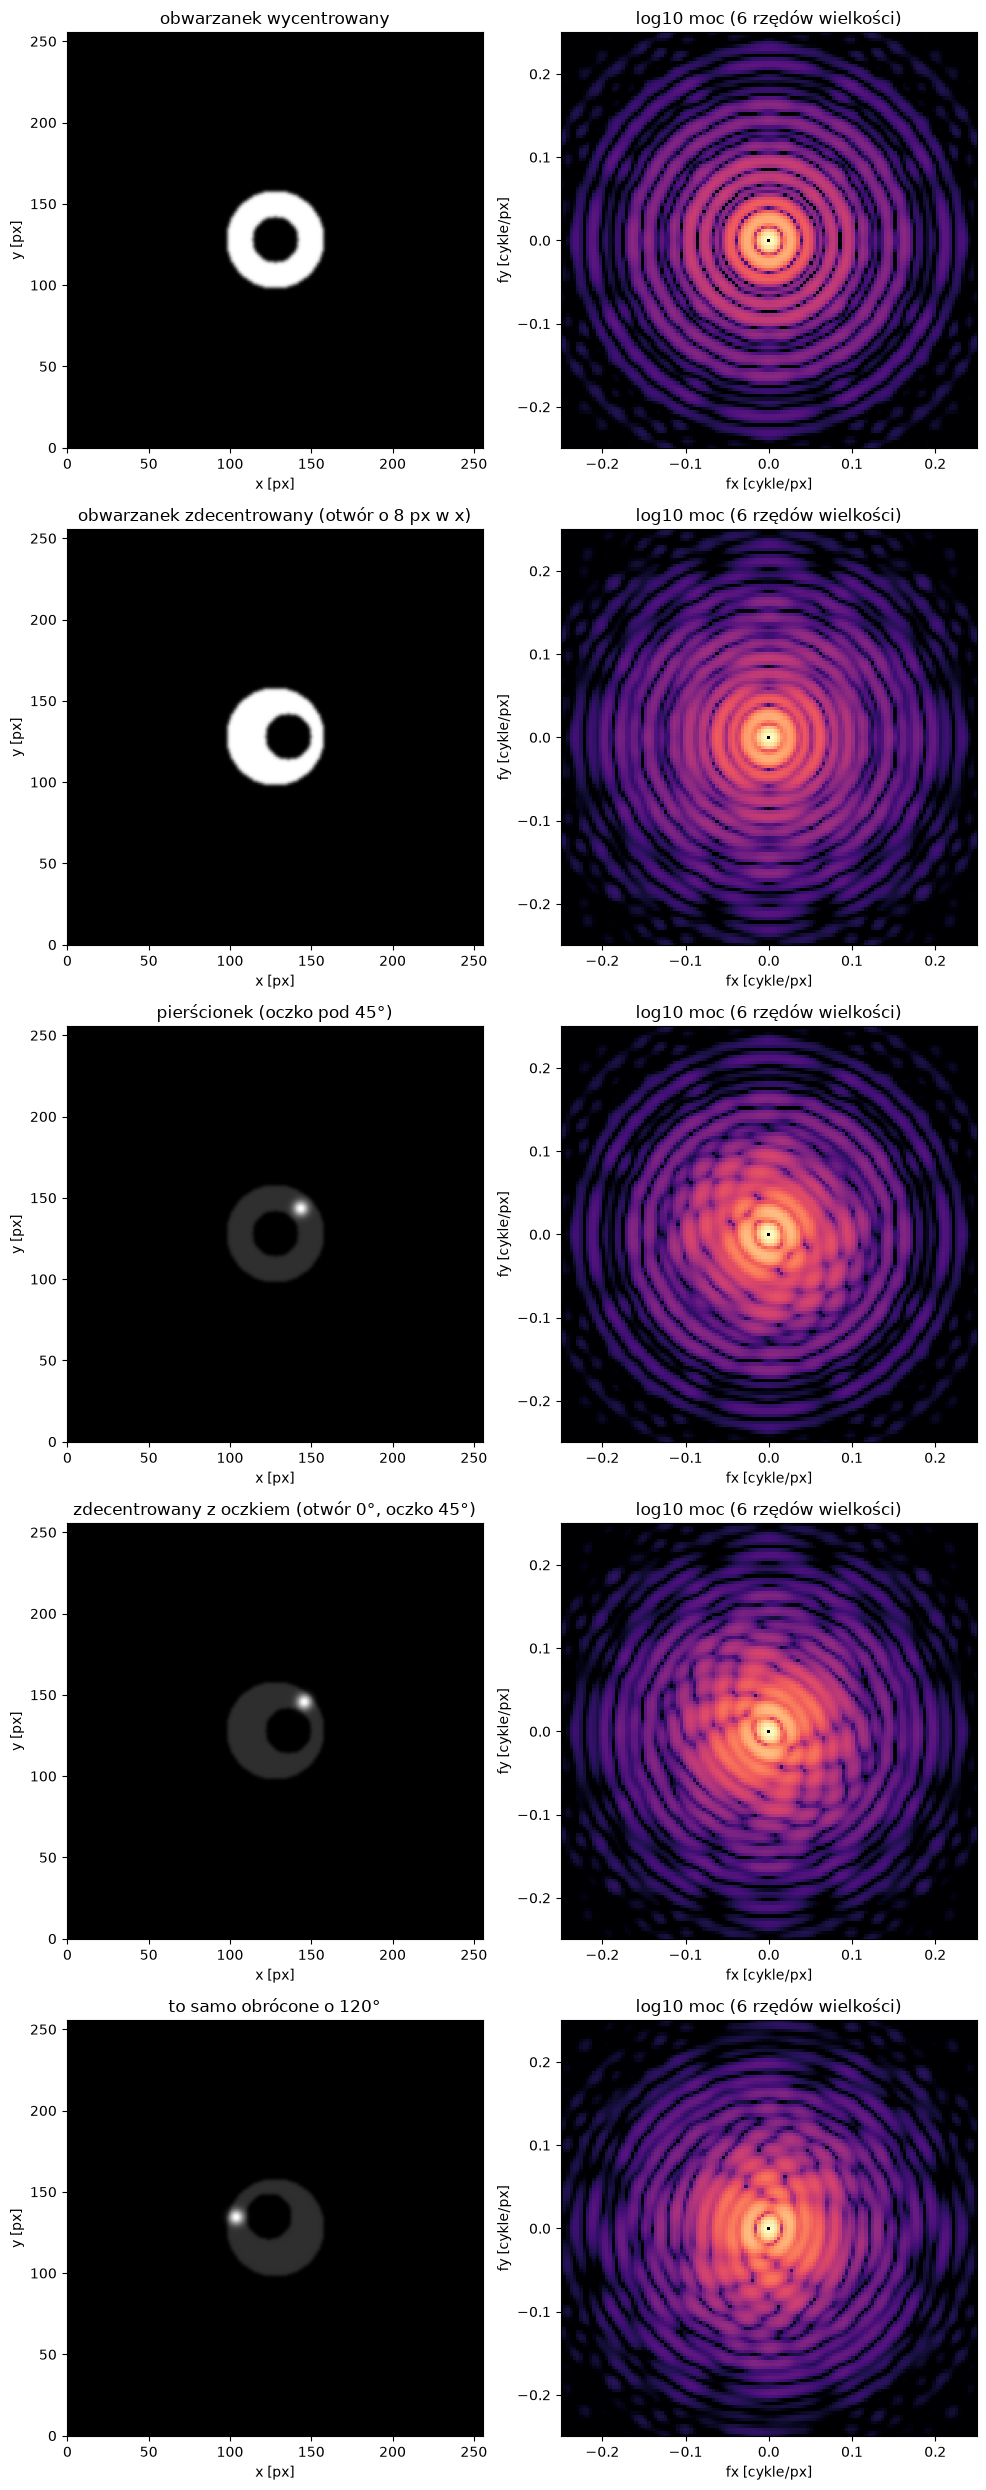

In [14]:
from scipy.ndimage import gaussian_filter

N2 = 256                                   # większe obrazki, żeby obwarzanek miał szczegóły
y2, x2 = np.mgrid[0:N2, 0:N2]
R_OUT, R_IN = 30, 14                       # promień zewnętrzny i otworu [px]
SHIFT = 8                                  # przesunięcie otworu w zdecentrowanym [px, w x]
SPOT_ANGLE = 45                            # pierścionek: gdzie na pierścieniu jest oczko [stopnie, od osi x]
SPOT_SIGMA = 3                             # rozmiar oczka [px]
SPOT_PEAK = 5                              # jasność oczka względem pierścienia
R_SPOT = 25                                # zdecentrowany z oczkiem: odległość oczka od środka [px]
ROT = 120                                  # o ile obrócić drugą wersję zdecentrowanego z oczkiem [stopnie]
ZOOM2 = 0.25                               # pokazywany zakres częstości [cykle/px]

c = N2 / 2
centered = (np.hypot(x2 - c, y2 - c) < R_OUT) & (np.hypot(x2 - c, y2 - c) > R_IN)
decentered = (np.hypot(x2 - c, y2 - c) < R_OUT) & (np.hypot(x2 - c - SHIFT, y2 - c) > R_IN)
sx2 = c + (R_OUT + R_IN) / 2 * np.cos(np.radians(SPOT_ANGLE))   # oczko w połowie szerokości pierścienia
sy2 = c + (R_OUT + R_IN) / 2 * np.sin(np.radians(SPOT_ANGLE))
spot = SPOT_PEAK * np.exp(-((x2 - sx2)**2 + (y2 - sy2)**2) / (2 * SPOT_SIGMA**2))

# zdecentrowany z oczkiem: otwór przesunięty w kierunku 0°, oczko pod SPOT_ANGLE
hx, hy = c + SHIFT, c
ox, oy = c + R_SPOT * np.cos(np.radians(SPOT_ANGLE)), c + R_SPOT * np.sin(np.radians(SPOT_ANGLE))
dec_spot = ((np.hypot(x2 - c, y2 - c) < R_OUT) & (np.hypot(x2 - hx, y2 - hy) > R_IN)) + SPOT_PEAK * np.exp(-((x2 - ox)**2 + (y2 - oy)**2) / (2 * SPOT_SIGMA**2))

# to samo obrócone o ROT: otwór w kierunku ROT, oczko pod SPOT_ANGLE + ROT
hx, hy = c + SHIFT * np.cos(np.radians(ROT)), c + SHIFT * np.sin(np.radians(ROT))
ox, oy = c + R_SPOT * np.cos(np.radians(SPOT_ANGLE + ROT)), c + R_SPOT * np.sin(np.radians(SPOT_ANGLE + ROT))
dec_spot_rot = ((np.hypot(x2 - c, y2 - c) < R_OUT) & (np.hypot(x2 - hx, y2 - hy) > R_IN)) + SPOT_PEAK * np.exp(-((x2 - ox)**2 + (y2 - oy)**2) / (2 * SPOT_SIGMA**2))

donuts = [
    ("obwarzanek wycentrowany", centered),
    (f"obwarzanek zdecentrowany (otwór o {SHIFT} px w x)", decentered),
    (f"pierścionek (oczko pod {SPOT_ANGLE}°)", centered.astype(float) + spot),
    (f"zdecentrowany z oczkiem (otwór 0°, oczko {SPOT_ANGLE}°)", dec_spot),
    (f"to samo obrócone o {ROT}°", dec_spot_rot),
]

f2 = np.fft.fftshift(np.fft.fftfreq(N2))
fig, axes = plt.subplots(len(donuts), 2, figsize=(10, 5 * len(donuts)))
for (title, im), (ax_im, ax_sp) in zip(donuts, axes):
    im = gaussian_filter(im.astype(float), 1)
    power = np.abs(np.fft.fftshift(np.fft.fft2(im - im.mean())))**2 / N2**2
    logp = np.log10(power + 1e-12)
    ax_im.imshow(im, origin="lower", cmap="gray")
    ax_im.set_title(title)
    ax_im.set_xlabel("x [px]")
    ax_im.set_ylabel("y [px]")
    ax_sp.imshow(logp, origin="lower", cmap="magma", vmin=logp.max() - 6, vmax=logp.max(), extent=[f2[0], f2[-1], f2[0], f2[-1]])
    ax_sp.set_xlim(-ZOOM2, ZOOM2)
    ax_sp.set_ylim(-ZOOM2, ZOOM2)
    ax_sp.set_title("log10 moc (6 rzędów wielkości)")
    ax_sp.set_xlabel("fx [cykle/px]")
    ax_sp.set_ylabel("fy [cykle/px]")
plt.tight_layout()
plt.show()


## Winietowanie, pyłki i obwarzanek w jednym flacie

Flat to kilka rzeczy naraz, każda na innej skali:

- **winietowanie** - powolny spadek jasności ku brzegom (tu o `VIG` w rogach). Skala całej klatki, więc w widmie siedzi w
  kilku najniższych częstościach przy samym środku.
- **pyłki** - cień pyłku na filtrze lub okienku to też obwarzanek: nieostry obraz źrenicy (z otworem po lustrze wtórnym),
  tylko ciemny zamiast jasnego i dużo mniejszy, bo pyłek leży blisko detektora. Kształt ten sam co ghost, inna skala i
  znak. Znak w widmie mocy nie gra roli, a skala tak: pierścienie w widmie są co ~1 / średnica, więc obwarzanek 15 razy
  mniejszy ma pierścienie 15 razy rzadsze i sięgające 15 razy dalej. Przy tym jest dużo słabszy (mała powierzchnia).
- **ghost** - duży, jasny obwarzanek (dodany), krawędzie rozmyte o `EDGE` px.
- **szum** - płaskie widmo, ten sam poziom wszędzie.

**Brzegi obrazka.** FFT traktuje obrazek tak, jakby powtarzał się w nieskończoność (lewy brzeg styka się z prawym, dolny z
górnym). Wycentrowane winietowanie ma na przeciwnych brzegach tę samą jasność, więc skoku nie ma - zostaje tylko załamanie
(nachylenie na lewym brzegu jest przeciwne niż na prawym), stąd słaby krzyż. Przesunięte
winietowanie ma na lewym brzegu inną jasność niż na prawym - na sklejeniu jest skok, a skok to ostra linia przez cały
obrazek, czyli w widmie długa linia wzdłuż osi (krzyż). To jest ten krzyż z sekcji 4 `zb08_red`. Okno Hanna wygasza obraz do
zera przy brzegach, skoku nie ma i krzyż znika (kosztem lekkiego rozmycia widma).

Ostatni wiersz: widmo uśrednione po okręgach (jak w sekcji 10 `zb08_red`) dla każdego składnika osobno. Widać, na jakich
okresach który składnik dominuje i gdzie się nakładają. Pyłki w tym przykładzie są w widmie całkiem pod szumem, choć na obrazku
widać je od razu: ich moc jest rozłożona na wiele częstości, a szum ma swoją wszędzie. Ghost dominuje aż do okresów ~20 px
(jego krawędź), winietowanie tylko na największych skalach.

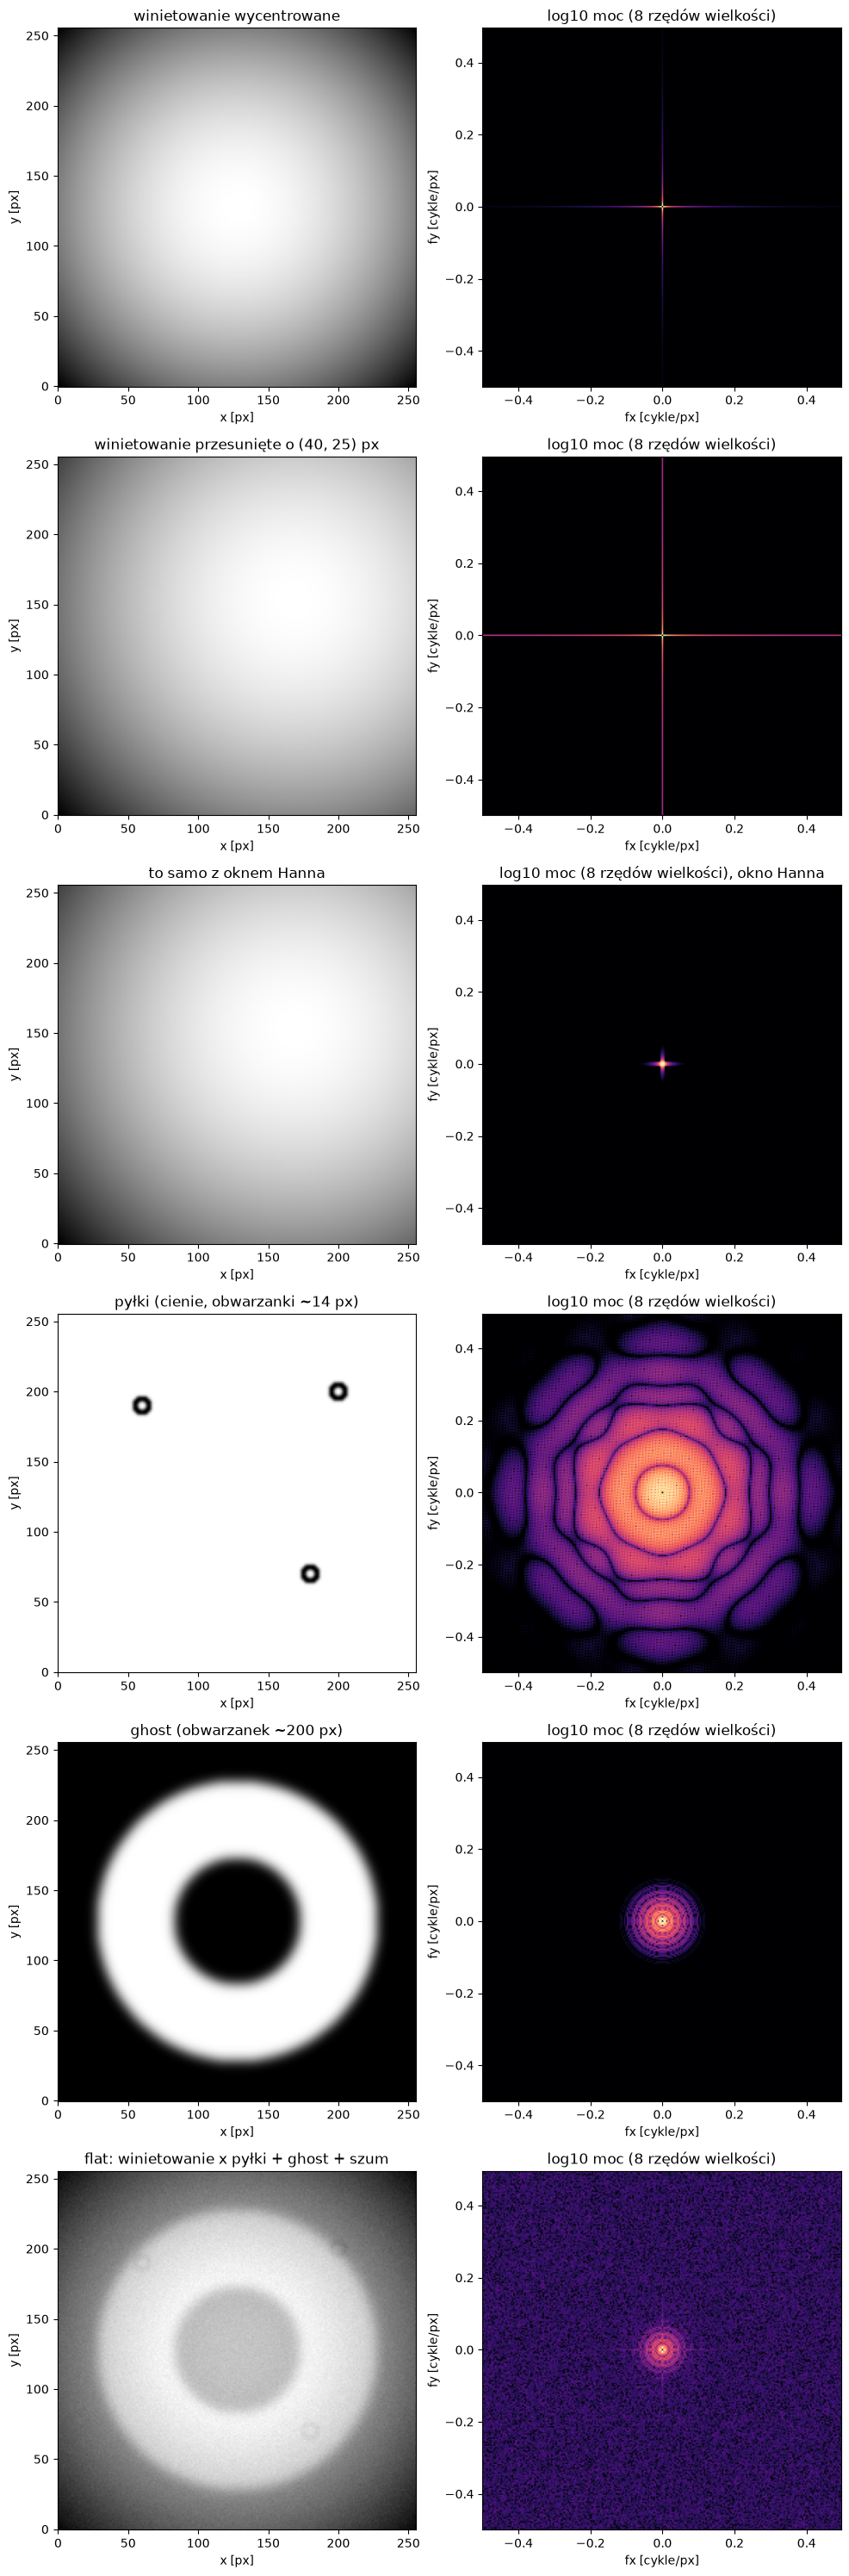

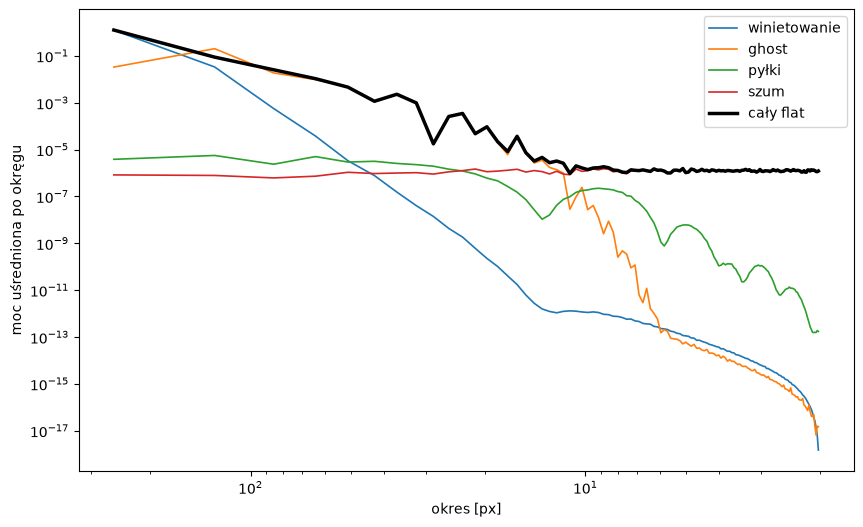

In [3]:
VIG = 0.15                                 # spadek jasności w rogach przez winietowanie
VIG_SHIFT = (40, 25)                       # przesunięcie środka winietowania w drugim przykładzie [px]
G_AMP, G_IN, G_OUT, EDGE = 0.05, 45, 100, 4    # ghost: jasność, promień otworu i zewnętrzny [px], rozmycie krawędzi [px]
DUST = [(60, 190), (180, 70), (200, 200)]  # pyłki: środki [px]
D_AMP, D_IN, D_OUT = 0.01, 3, 7            # pyłek: głębokość cienia, promień otworu i zewnętrzny [px]
NOISE = 0.003                              # szum piksel-do-piksela

c = N2 / 2
r_corner = np.hypot(c, c)
vig = 1 - VIG * (np.hypot(x2 - c, y2 - c) / r_corner)**2
vig_off = 1 - VIG * (np.hypot(x2 - c - VIG_SHIFT[0], y2 - c - VIG_SHIFT[1]) / r_corner)**2
rr = np.hypot(x2 - c, y2 - c)
ghost = G_AMP * gaussian_filter(((rr > G_IN) & (rr < G_OUT)).astype(float), EDGE)
dust = np.zeros((N2, N2))
for dx, dy in DUST:
    rd = np.hypot(x2 - dx, y2 - dy)
    dust = dust - D_AMP * gaussian_filter(((rd > D_IN) & (rd < D_OUT)).astype(float), 1)
noise = rng.normal(0, NOISE, (N2, N2))
flat = vig * (1 + dust) + ghost + noise
hann = np.outer(np.hanning(N2), np.hanning(N2))

flats_ex = [
    ("winietowanie wycentrowane", vig, False),
    (f"winietowanie przesunięte o {VIG_SHIFT} px", vig_off, False),
    ("to samo z oknem Hanna", vig_off, True),
    ("pyłki (cienie, obwarzanki ~14 px)", 1 + dust, False),
    ("ghost (obwarzanek ~200 px)", 1 + ghost, False),
    ("flat: winietowanie x pyłki + ghost + szum", flat, False),
]

fig, axes = plt.subplots(len(flats_ex), 2, figsize=(10, 5 * len(flats_ex)))
for (title, im, window), (ax_im, ax_sp) in zip(flats_ex, axes):
    data = im - im.mean()
    if window:
        data = data * hann
    power = np.abs(np.fft.fftshift(np.fft.fft2(data)))**2 / N2**2
    logp = np.log10(power + 1e-14)
    ax_im.imshow(im, origin="lower", cmap="gray")
    ax_im.set_title(title)
    ax_im.set_xlabel("x [px]")
    ax_im.set_ylabel("y [px]")
    ax_sp.imshow(logp, origin="lower", cmap="magma", vmin=logp.max() - 8, vmax=logp.max(), extent=[f2[0], f2[-1], f2[0], f2[-1]])
    ax_sp.set_title("log10 moc (8 rzędów wielkości)" + (", okno Hanna" if window else ""))
    ax_sp.set_xlabel("fx [cykle/px]")
    ax_sp.set_ylabel("fy [cykle/px]")
plt.tight_layout()
plt.show()

# widmo uśrednione po okręgach, każdy składnik osobno (wszystkie z oknem Hanna)
k = np.hypot(*np.meshgrid(np.arange(N2) - N2 // 2, np.arange(N2) - N2 // 2)).astype(int)
fig, ax = plt.subplots(figsize=(10, 6))
for title, im in [("winietowanie", vig), ("ghost", ghost), ("pyłki", dust), ("szum", noise), ("cały flat", flat)]:
    power = np.abs(np.fft.fftshift(np.fft.fft2((im - im.mean()) * hann)))**2 / N2**2
    radial = np.bincount(k.ravel(), power.ravel()) / np.bincount(k.ravel())
    ax.loglog(N2 / np.arange(1, N2 // 2), radial[1:N2 // 2], label=title, lw=2.5 if title == "cały flat" else 1.2, color="k" if title == "cały flat" else None)
ax.invert_xaxis()
ax.set_xlabel("okres [px]")
ax.set_ylabel("moc uśredniona po okręgu")
ax.legend()
plt.show()

## Jak FFT układa częstości (1D, N = 8)

**Co znaczy indeks k.** Sygnał ma N pikseli.
- k = 0 to średnia.
- k = 1 to jedna **cała** fala na całą długość, okres N px.
- k to k fal na długość, okres N/k px.
- Najwyższa częstość to k = N/2, okres **2 px** (Nyquist, 0.5 cykla/px). Fali o okresie 1 px nie widać: próbkujemy ją zawsze w tej samej fazie, więc wygląda jak stała.

**Co jest za połową (k > N/2).** FFT zwraca N liczb, indeksy 0 … N-1. W pikselach całkowitych indeks k jest nie do odróżnienia
od k - N, bo e^(2πi·k·n/N) = e^(2πi·(k-N)·n/N). Indeks N-1 to więc częstość -1, N-2 to -2 itd. Kolejność na wyjściu FFT:

```
indeks:      0   1   2   3   4   5   6   7
częstość:    0   1   2   3  -4  -3  -2  -1      (np.fft.fftfreq(8) * 8)
```

**`fftshift`** tylko przestawia te same N liczb w kolejność -4 … -1, 0, 1 … 3, żeby zero było w środku, a częstości rosły od
lewej do prawej. Niczego nie dubluje i nic nie dodaje.

**Skąd dwie kropki.** FFT rozkłada nie na sinusy, tylko na zespolone fale e^(iωx). Rzeczywisty sinus to suma dwóch takich
fal: sin(ωx) = (e^(iωx) - e^(-iωx)) / 2i, więc potrzebuje częstości +f i -f.

**Dublowanie jest, ale nie przez fftshift.** Dla każdego rzeczywistego sygnału F(-f) = sprzężenie F(f), więc moc w -f jest
taka sama jak w +f. Połowa widma jest nadmiarowa już na wyjściu FFT (indeksy k i N-k). `np.fft.rfft` zwraca tylko tę
połowę. W 2D symetria jest środkowa, (fx, fy) ↔ (-fx, -fy): wystarcza półpłaszczyzna, ale nie ćwiartka, bo (fx, fy) i
(fx, -fy) to różne kierunki (np. +45° i -45°). Dlatego rysujemy całą płaszczyznę i każdy wzór widać dwa razy,
symetrycznie przez środek.

In [15]:
N8 = 8
n = np.arange(N8)
s = np.sin(2 * np.pi * n / N8)                   # jedna cała fala na 8 pikseli (k = 1)

F = np.fft.fft(s)
print("sygnał:            ", np.round(s, 3))
print()
print("bez fftshift")
print("  częstość k:      ", np.fft.fftfreq(N8) * N8)
print("  moc |F|²/N:      ", np.round(np.abs(F)**2 / N8, 3))
print()
print("po fftshift (te same liczby, inna kolejność)")
print("  częstość k:      ", np.fft.fftshift(np.fft.fftfreq(N8)) * N8)
print("  moc |F|²/N:      ", np.round(np.abs(np.fft.fftshift(F))**2 / N8, 3))
print()
print("rfft (tylko k >= 0, bez nadmiarowej połowy)")
print("  częstość k:      ", np.fft.rfftfreq(N8) * N8)
print("  moc |F|²/N:      ", np.round(np.abs(np.fft.rfft(s))**2 / N8, 3))
print()
# k = 7 i k = -1 to w pikselach ten sam sygnał: sin(2π·7n/8) = sin(2π·(-1)n/8) = -sin(2π·n/8)
print("sin k = 7:         ", np.round(np.sin(2 * np.pi * 7 * n / N8), 3))
print("sin k = -1:        ", np.round(np.sin(2 * np.pi * -1 * n / N8), 3))


sygnał:             [ 0.     0.707  1.     0.707  0.    -0.707 -1.    -0.707]

bez fftshift
  częstość k:       [ 0.  1.  2.  3. -4. -3. -2. -1.]
  moc |F|²/N:       [0. 2. 0. 0. 0. 0. 0. 2.]

po fftshift (te same liczby, inna kolejność)
  częstość k:       [-4. -3. -2. -1.  0.  1.  2.  3.]
  moc |F|²/N:       [0. 0. 0. 2. 0. 2. 0. 0.]

rfft (tylko k >= 0, bez nadmiarowej połowy)
  częstość k:       [0. 1. 2. 3. 4.]
  moc |F|²/N:       [0. 2. 0. 0. 0.]

sin k = 7:          [ 0.    -0.707 -1.    -0.707  0.     0.707  1.     0.707]
sin k = -1:         [-0.    -0.707 -1.    -0.707 -0.     0.707  1.     0.707]
